# 04 — Huấn luyện U-Net M1

Notebook huấn luyện U-Net tự cài trên **toàn bộ tập Kvasir train** theo split cố định: mặc định **700 ảnh train / 150 ảnh validation**. Validation không cập nhật trọng số; test và ClinicDB dành cho đánh giá cuối.

Logic nằm trong module Python. Chuẩn bị dữ liệu/split bằng notebook 02, kiểm tra preprocessing bằng notebook 03 và cài `requirements-training.txt`. Chọn kernel phù hợp, **Restart Kernel → Run All** để bắt đầu một lượt train đầy đủ mới, tối đa 200 epoch. Mỗi lượt lưu riêng tại `results/M1/<run_id>/`.

Thứ tự: xem cấu hình → xem kiến trúc → train → xem metric, biểu đồ và dự đoán. Muốn xem lại kết quả đã lưu, chỉ chạy ô cuối **Vẽ lại biểu đồ**, không cần Run All.

In [9]:
import sys
from pathlib import Path

start = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (start, *start.parents)
                     if (p / "src/datasets").is_dir() and (p / "README.md").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Mở notebook trong cây thư mục repo.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import torch
from PIL import Image
from IPython.display import display
from src.models.unet import UNet
from src.training import run_training, select_device
from src.utils import load_config
from src.visualization import save_architecture

config = load_config(PROJECT_ROOT / "configs/unet.yaml")
device = select_device()
print("PyTorch:", torch.__version__, "| Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(device))

PyTorch: 2.9.1+cu126 | Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


## Kiến trúc M1

4 mức encoder `32/64/128/256`, bottleneck `512`, mỗi khối hai Conv3×3 + ReLU. MaxPool downsampling, ConvTranspose2d upsampling và nối skip. Conv1×1 cuối xuất **một kênh logits**, không sigmoid. Model khởi tạo ngẫu nhiên; không tải pretrained weights.

Loss là **BCEWithLogits + soft Dice**, trọng số 1:1; cả hai bỏ padding bằng `valid_mask`. Train đầy đủ dùng augmentation lật/xoay đã có ở bước 3; chưa thêm brightness/contrast.

Số tham số: 7,760,097


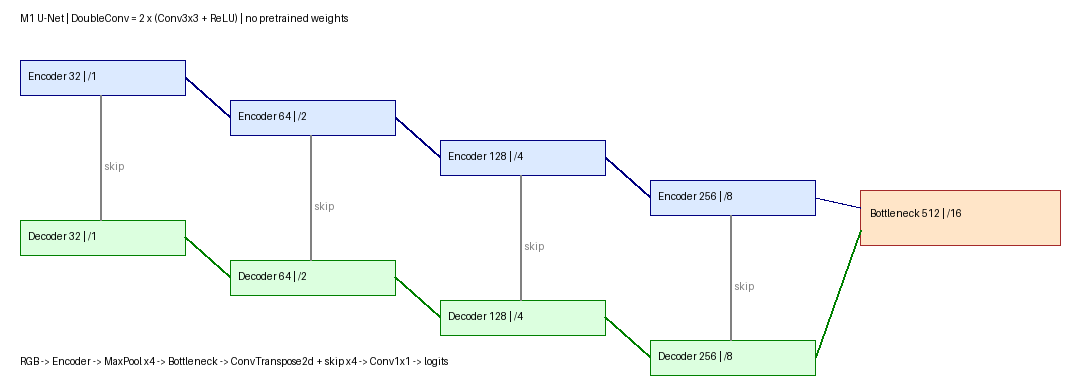

In [10]:
model = UNet(channels=config["model"]["channels"], output_channels=1)
print("Số tham số:", f"{sum(p.numel() for p in model.parameters()):,}")
del model
figure = PROJECT_ROOT / "results/figures/M1_architecture.png"
figure.parent.mkdir(parents=True, exist_ok=True)
save_architecture(config["model"]["channels"], figure)
display(Image.open(figure))

## Huấn luyện trên toàn bộ tập train

Đọc cấu hình `configs/unet.yaml`: batch size 8, Adam LR 1e-4, tối đa 200 epoch. Scheduler giảm LR theo validation Dice; early stopping sau 20 epoch liên tiếp không vượt best Dice. Khi bằng điểm, giữ checkpoint sớm hơn.

Augmentation lật/xoay chỉ áp dụng cho train. Loss BCE + soft Dice loại pixel padding. Validation bỏ padding, resize logits về kích thước gốc rồi sigmoid/threshold 0.5, tính Dice/IoU từng ảnh và lấy trung bình. Log mỗi epoch vẫn được in; tắt thanh tiến trình từng batch để tránh lỗi widget và giới hạn output của notebook.

Hoàn tất rà ứng viên gần trùng ở notebook 02 trước khi chốt kết quả chính thức. Khi review/screening chưa cập nhật, code ghi trạng thái provisional trong metadata.

In [11]:
full_run = run_training(PROJECT_ROOT, mode="full", progress=False)

Run: D:\DHCN\HK5\DL\Medical-Image-Segmentation\results\M1\20261124T081030Z_full_seed42_e67215
Mode=full, device=cuda, AMP=True, counts={'train': 700, 'val': 150}
NOTE: duplicate screening/review is not current. This run is provisional; finish notebook 02 before final reporting.
Epoch 1/200 | train_loss=1.2768 | val_loss=1.1328 | val_dice=0.0000 | val_iou=0.0000 | lr=0.0001
Epoch 2/200 | train_loss=1.1301 | val_loss=1.1139 | val_dice=0.3010 | val_iou=0.2044 | lr=0.0001
Epoch 3/200 | train_loss=1.1253 | val_loss=1.1091 | val_dice=0.3406 | val_iou=0.2307 | lr=0.0001
Epoch 4/200 | train_loss=1.1154 | val_loss=1.0915 | val_dice=0.3840 | val_iou=0.2665 | lr=0.0001
Epoch 5/200 | train_loss=1.0950 | val_loss=1.0696 | val_dice=0.3764 | val_iou=0.2594 | lr=0.0001
Epoch 6/200 | train_loss=1.0902 | val_loss=1.0682 | val_dice=0.3586 | val_iou=0.2443 | lr=0.0001
Epoch 7/200 | train_loss=1.0672 | val_loss=1.0621 | val_dice=0.2903 | val_iou=0.1948 | lr=0.0001
Epoch 8/200 | train_loss=1.0519 | val_loss

## Kết quả M1

Biểu đồ loss, Dice, IoU và learning rate đánh dấu epoch có validation Dice cao nhất. Metric train đo trên vùng hợp lệ ở đầu vào; metric validation đo tại kích thước ảnh gốc. Overlay gồm ảnh gốc, mask thật và dự đoán.

Số ảnh: {'train': 700, 'val': 150}
Số epoch đã chạy: 127
Best epoch: 107
Best validation Dice: 0.7999
Thư mục kết quả: D:\DHCN\HK5\DL\Medical-Image-Segmentation\results\M1\20261124T081030Z_full_seed42_e67215


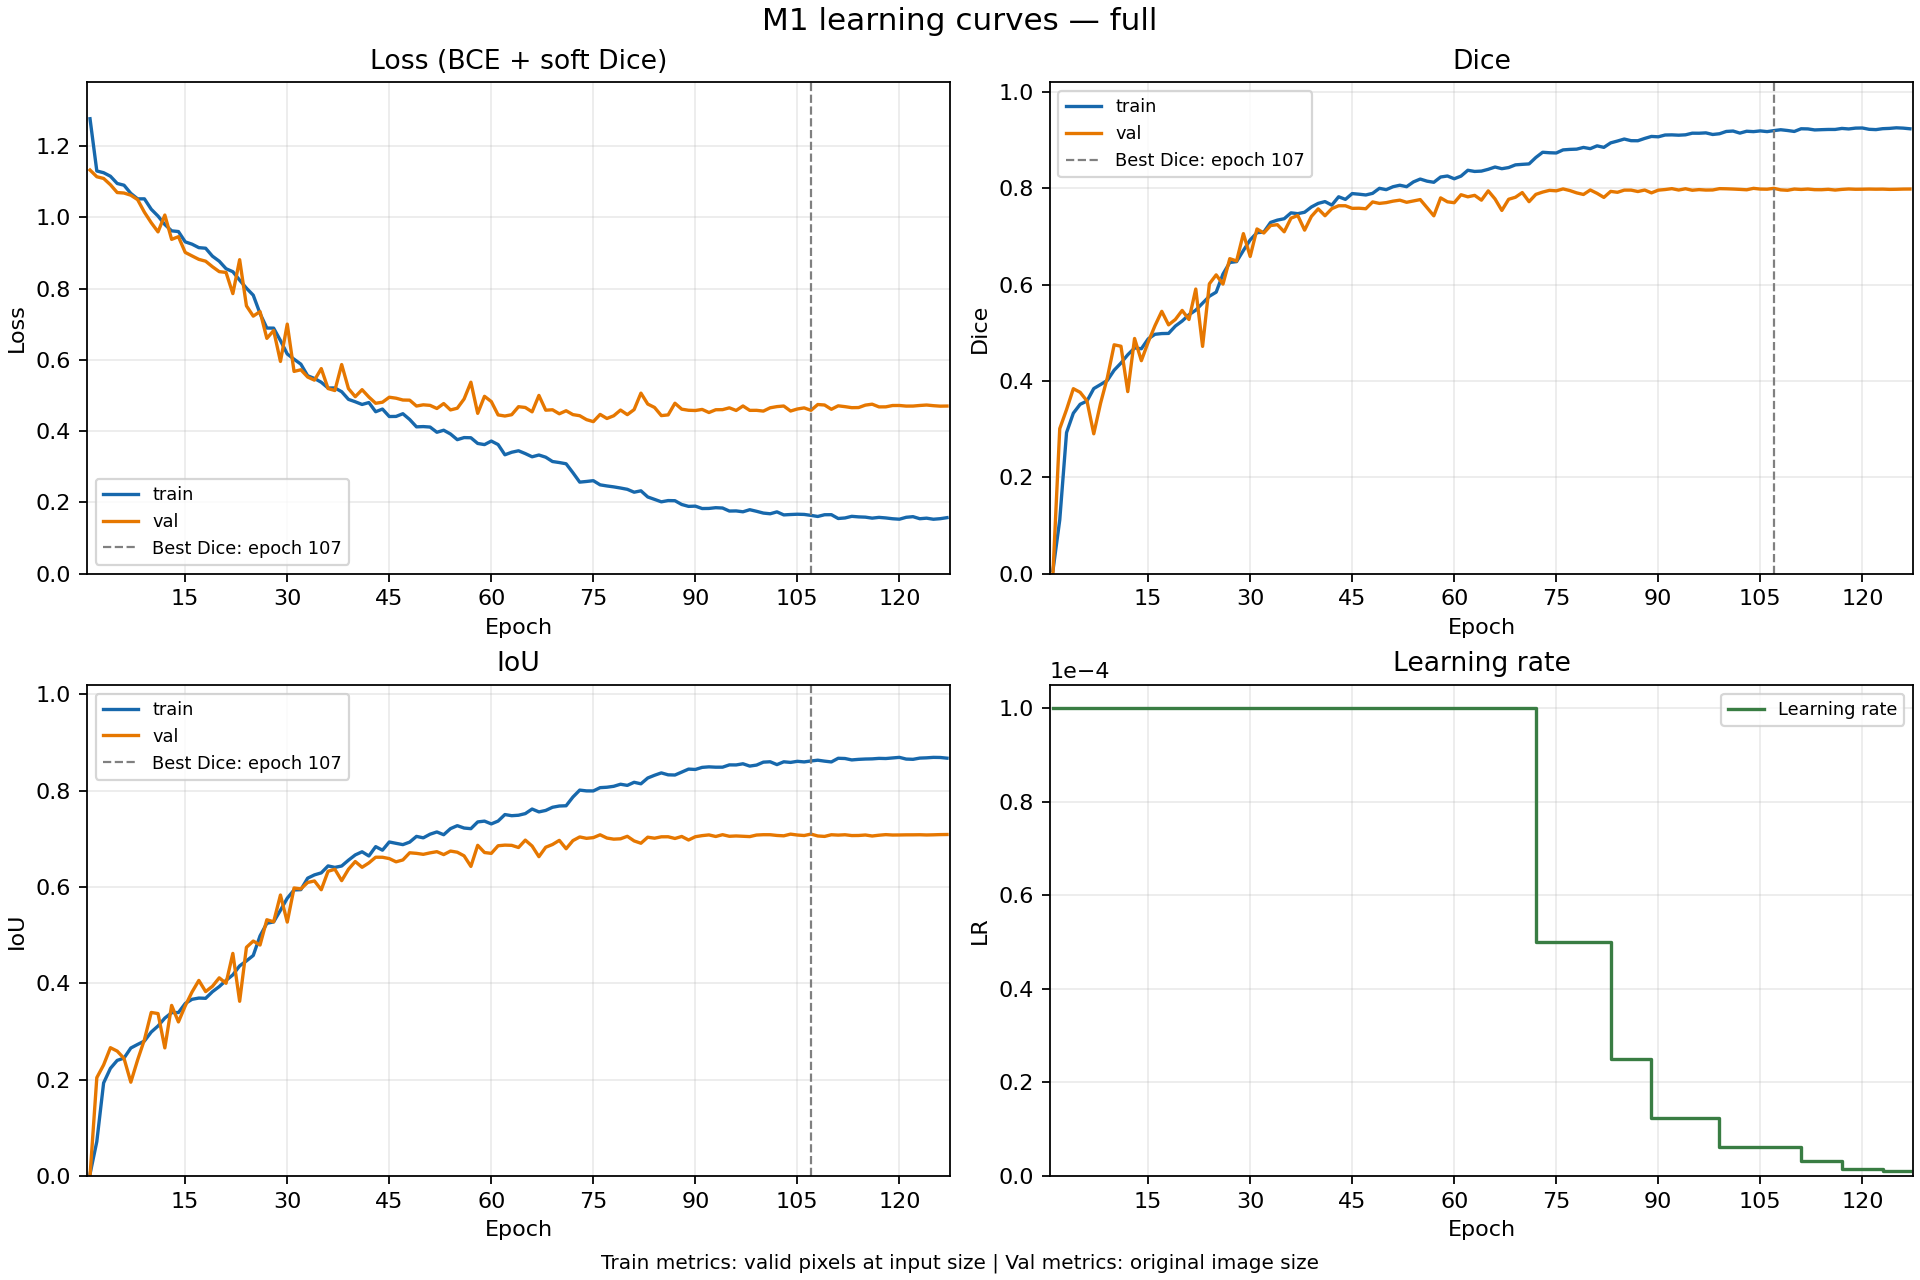

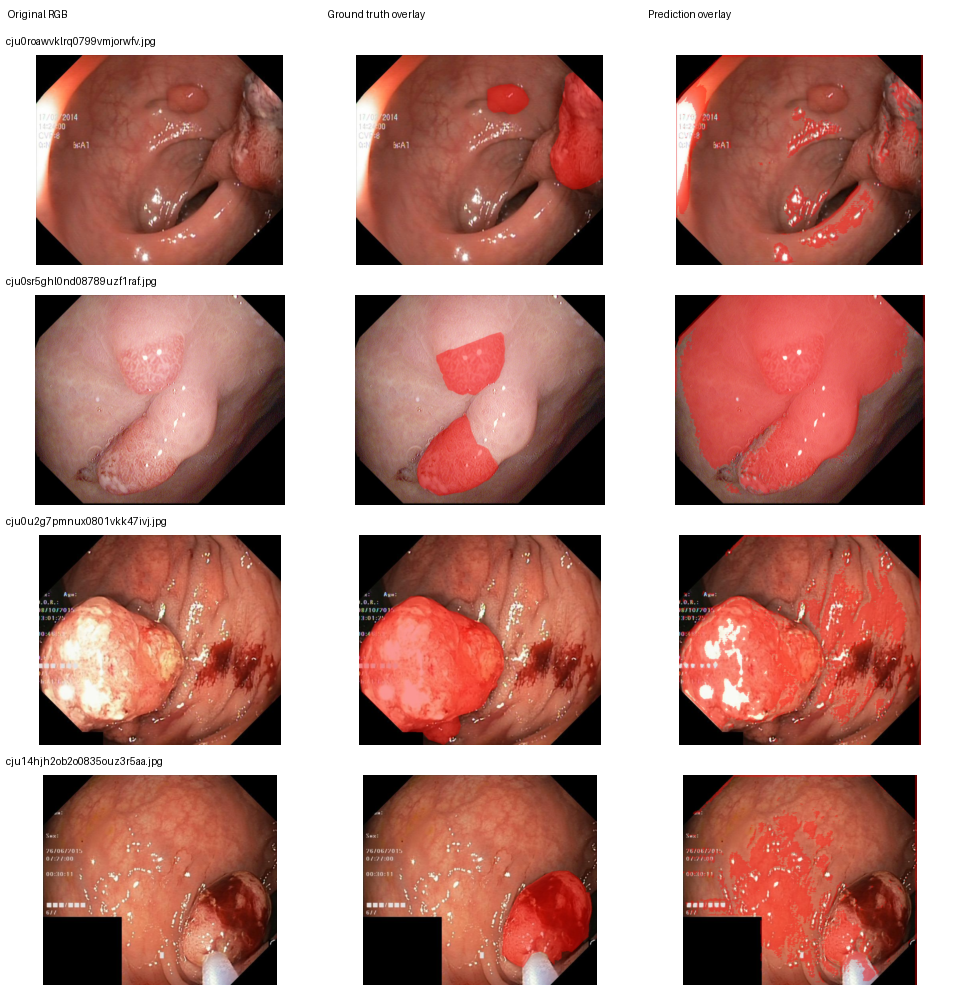

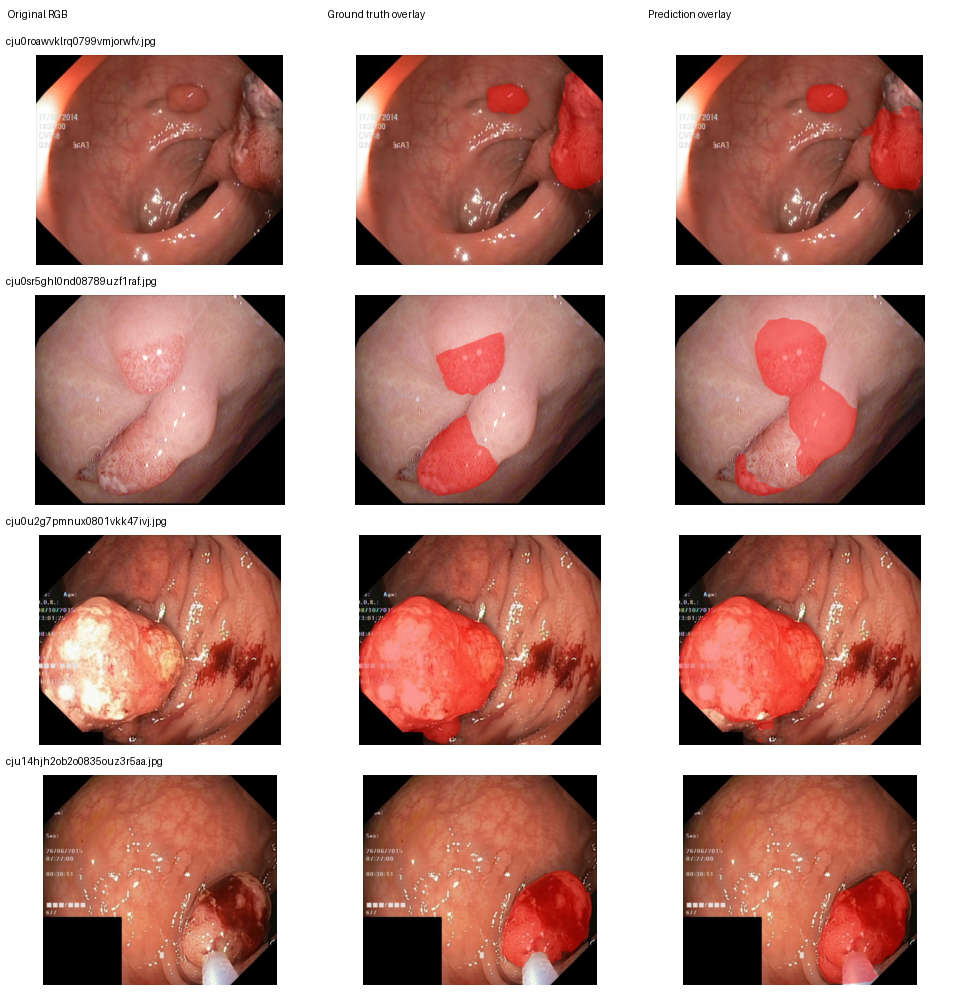

In [14]:
import importlib
import src.visualization as visualization
importlib.reload(visualization)
plot_run_history = visualization.plot_run_history

metadata = full_run["metadata"]
print("Số ảnh:", metadata["counts"])
print("Số epoch đã chạy:", metadata["epochs_completed"])
print("Best epoch:", metadata["best_epoch"])
print("Best validation Dice:", f"{metadata['best_dice']:.4f}")
print("Thư mục kết quả:", full_run["run_dir"])

figure = plot_run_history(full_run["run_dir"])
for path in (figure, full_run["run_dir"] / "predictions_before.png",
             full_run["run_dir"] / "predictions_best.png"):
    with Image.open(path) as image:
        display(image.copy())

## Kết quả được lưu tự động

- `best.pt`, `last.pt`: model, optimizer, scheduler, scaler và trạng thái RNG. Mỗi lệnh khởi chạy mới; hiện chưa có CLI resume.
- `history.csv`: loss/BCE/soft Dice, Dice/IoU/Precision/Recall, LR và thời gian mỗi epoch.
- `best_val_metrics.csv`: metric từng ảnh validation tại best epoch.
- `learning_curves.png`, `architecture.png`, `predictions_before.png`, `predictions_best.png`: biểu đồ và hình minh họa.
- `config.yaml`, `metadata.json`: cấu hình thực tế, seed, thiết bị/precision, phiên bản, commit/hash code/split và tình trạng review.

Không dùng test/ClinicDB để chọn hyperparameter. Trước commit, Clear All Outputs; không đưa checkpoint hoặc kết quả sinh ra lên Git. Lệnh terminal tương đương: `python -m scripts.train --mode full --quiet`.

## Vẽ lại biểu đồ từ kết quả đã lưu — không train lại

Chạy riêng ô dưới sau khi restart kernel để xem loss, Dice, IoU và learning rate từ CSV. `RUN_DIR=None` chọn **lượt train đầy đủ** có lịch sử cập nhật mới nhất. Có thể gán `RUN_DIR="results/M1/<run_id>"` để chọn một lượt cụ thể. Hình lưu thành `learning_curves.png` trong thư mục đó.

Đang vẽ run: D:\DHCN\HK5\DL\Medical-Image-Segmentation\results\M1\20261124T081030Z_full_seed42_e67215
Số ảnh: {'train': 700, 'val': 150}
Hình đã lưu: D:\DHCN\HK5\DL\Medical-Image-Segmentation\results\M1\20261124T081030Z_full_seed42_e67215\learning_curves.png


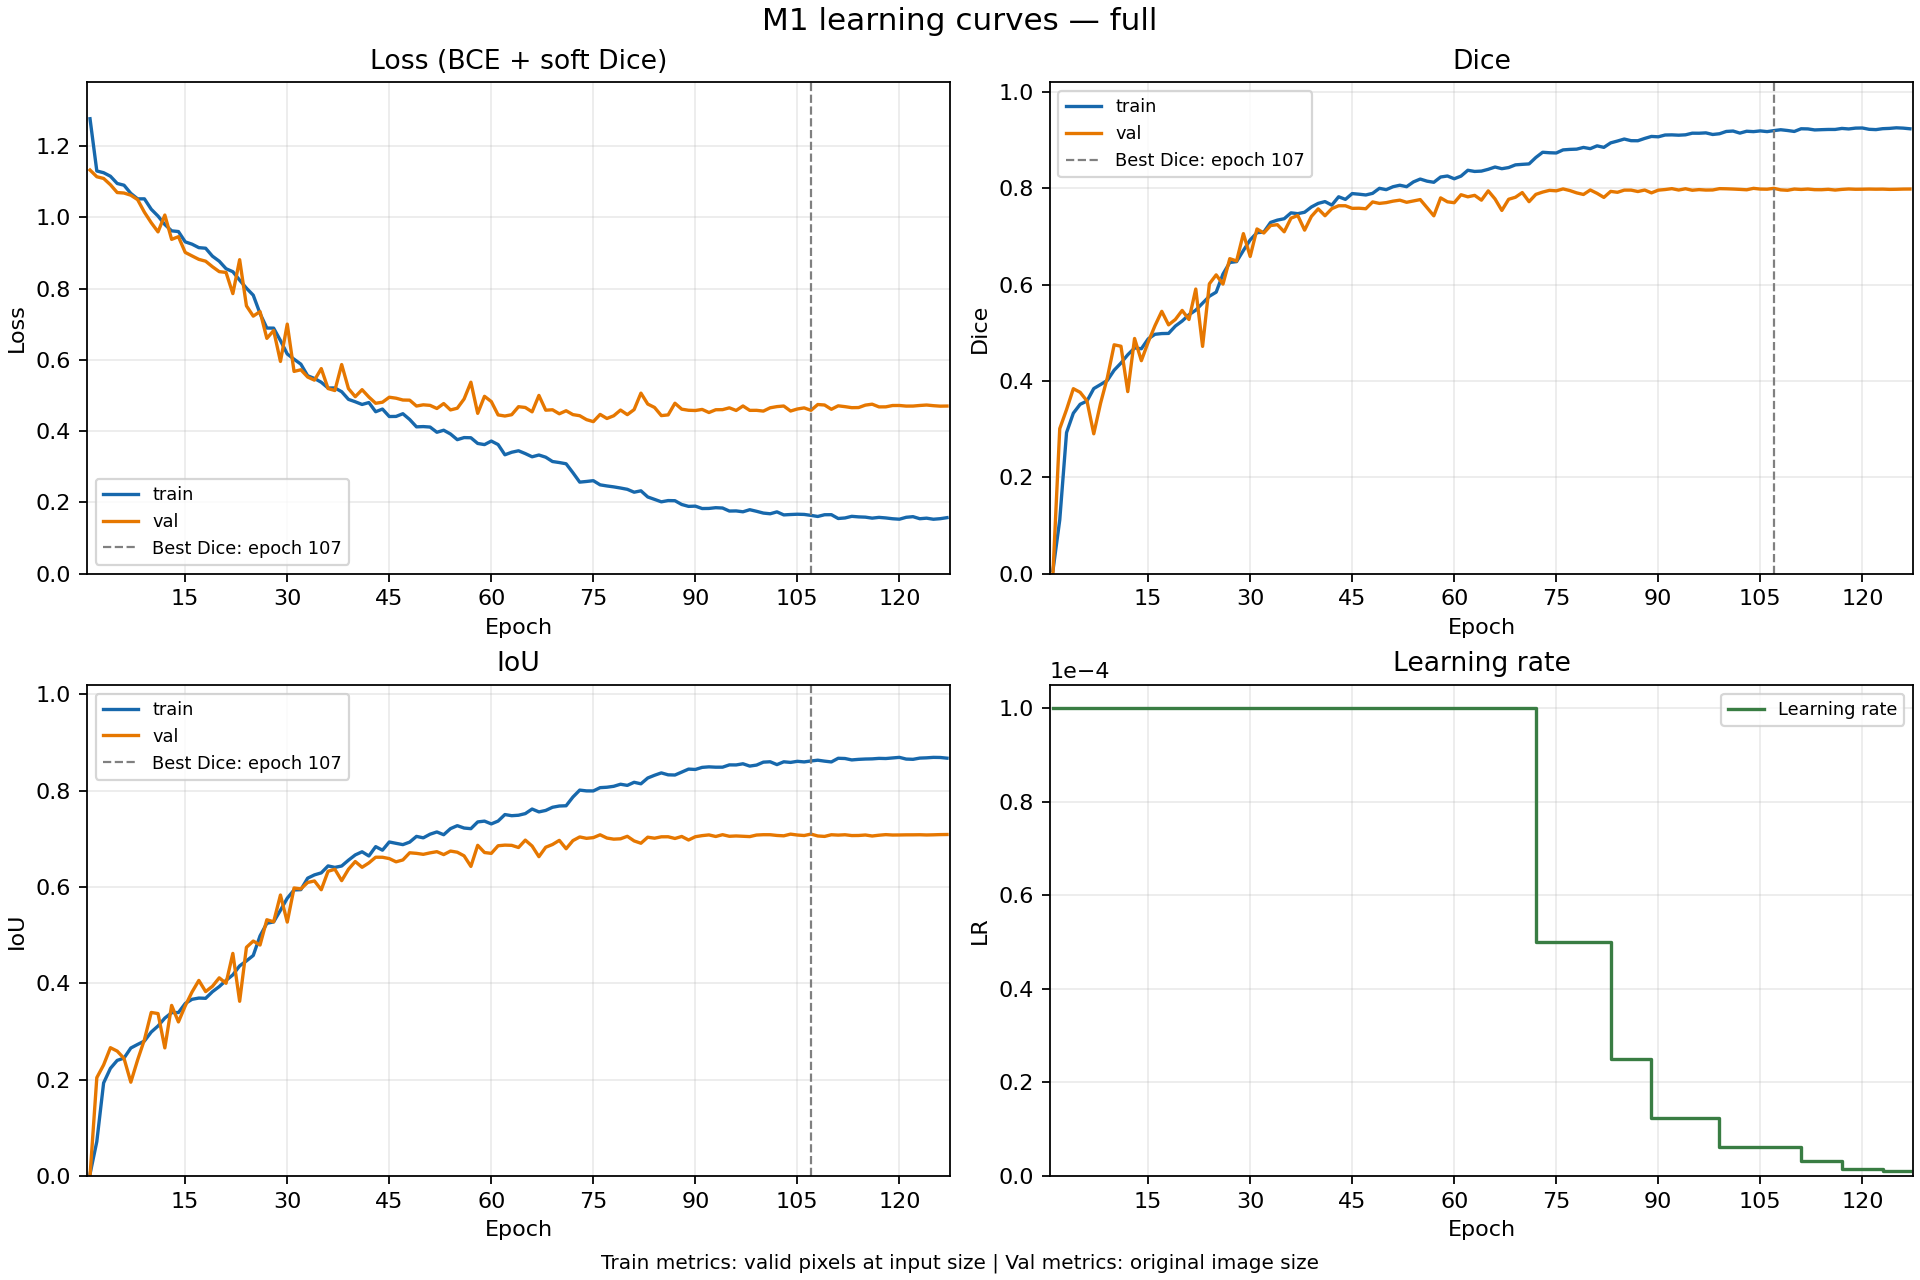

In [15]:
import sys
import json
import importlib
from pathlib import Path
from PIL import Image
from IPython.display import display

start = Path.cwd().resolve()
root = next((p for p in (start, *start.parents)
             if (p / "src/datasets").is_dir() and (p / "README.md").is_file()), None)
if root is None:
    raise FileNotFoundError("Mở notebook trong cây thư mục repo.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import src.visualization as visualization
importlib.reload(visualization)

RUN_DIR = None  # hoặc "results/M1/<run_id>" để chọn lượt cụ thể
if RUN_DIR is None:
    histories = []
    for history in (root / "results/M1").glob("*/history.csv"):
        metadata_file = history.parent / "metadata.json"
        if metadata_file.exists():
            info = json.loads(metadata_file.read_text(encoding="utf-8"))
            if info.get("mode") == "full":
                histories.append(history)
    if not histories:
        raise FileNotFoundError("Chưa có lịch sử train đầy đủ. Chọn một run đã lưu hoặc chạy phần huấn luyện trước.")
    run_dir = max(histories, key=lambda p: p.stat().st_mtime).parent
else:
    run_dir = Path(RUN_DIR)
    if not run_dir.is_absolute():
        run_dir = root / run_dir

metadata = json.loads((run_dir / "metadata.json").read_text(encoding="utf-8"))
if metadata.get("mode") != "full":
    raise ValueError("Hãy chọn thư mục của một lượt train đầy đủ (mode=full).")
print("Đang vẽ run:", run_dir)
print("Số ảnh:", metadata.get("counts"))
figure = visualization.plot_run_history(run_dir)
print("Hình đã lưu:", figure)
with Image.open(figure) as image:
    display(image.copy())